# APRAU 2026/27 - Grupo 08
## Parte 2: Regressão Linear Múltipla (`target_regression`)

Ponto 3 do enunciado: ajustar um modelo de regressão linear múltipla com várias *features*, experimentar diferentes combinações de variáveis, escolher o grupo com melhor desempenho e avaliá-lo com $R^2$, MAE e RMSE.

Este notebook usa **apenas o que consta nos slides de Regressão Linear** (Simple & Multiple Linear Regression):

| Tema dos slides | Onde aparece aqui |
|---|---|
| Modelo $Y = \beta_0 + \beta_1 X_1 + \dots + \beta_p X_p + \varepsilon$ e estimação por mínimos quadrados (RSS) | Secção 2 |
| Forma matricial $\hat\beta = (X^T X)^{-1} X^T y$ (exige $X^T X$ não singular) | Secção 2 |
| Correlação entre preditores (`advertising.corr()`) e colinearidade | Secção 3 |
| `statsmodels` OLS: coeficientes, p-values, $R^2$ e estatística F | Secção 4 (pergunta 1) |
| Comparar subconjuntos de preditores | Secção 5 (pergunta 2) |
| $R^2 = 1 - RSS/TSS$ | Secção 6 (pergunta 3) |
| `scikit-learn` `LinearRegression`, `fit` e `predict` | Secções 5 e 7 (pergunta 4) |
| Problemas potenciais (não linearidade, variância não constante dos erros) | Secção 8 |

Os slides só trabalham com preditores numéricos, por isso as variáveis categóricas são primeiro codificadas como numéricas (secção 1) e verifica-se a escala dos preditores (secção 3). A avaliação usa um *hold-out* (80% treino / 20% teste), como permite o enunciado.

In [1]:
# ============================================================
# SETUP
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
import sklearn.linear_model as skl_lm
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
df = pd.read_csv("dataset_grupo_08.csv")

---
## 1. Dados, codificação e partição *hold-out*

`target_regression` é a variável resposta $Y$. A regressão linear só aceita preditores numéricos, por isso as variáveis categóricas são codificadas primeiro (a mesma codificação do apêndice do `task1`):

| Tipo | Variáveis | Codificação |
|---|---|---|
| ordinal | `physical_activity`, `stress_level`, `sugar_consumption` | 1, 2, 3 pela ordem natural |
| binária | `gender`, `family_history`, `low_hdl_cholesterol`, `high_ldl_cholesterol` | 0/1 (`Female` e `Yes` = 1) |
| nominal | `smoking`, `education_level`, `employment_status` | *one-hot*, sem a primeira categoria (referência) |

A célula de codificação é a do apêndice do `task1` (inclui `bmi_level` e `age_level`). Na célula seguinte retiram-se `bmi_level` e `age_level`, que são categorizações de `age` e `bmi` (secção 5 do `task1`), e uma categoria de referência por variável *one-hot* (`smoking_Never`, `education_level_Primary`, `employment_status_Unemployed`), porque as colunas completas somam 1 e seriam combinação linear do termo constante (singularidade, secção 2).

A codificação não usa estatísticas dos dados, por isso faz-se antes da partição sem fuga de informação. A partição é feita uma só vez e o conjunto de teste só serve para avaliar.


In [2]:
# Create a copy to preserve the original dataframe
df_encoded = df.copy()

# Identificar as colunas alvo
target_columns = ["target_class", "target_regression"]

# 1. Ordinal encoding
ordinal_mappings = {
    "bmi_level": {
        "Underweight": 1,
        "Normal": 2,
        "Overweight": 3,
        "Obese": 4
    },
    "physical_activity": {
        "Low": 1,
        "Moderate": 2,
        "High": 3
    },
    "stress_level": {
        "Low": 1,
        "Medium": 2,
        "High": 3
    },
    "sugar_consumption": {
        "Low": 1,
        "Medium": 2,
        "High": 3
    }
}

for column, mapping in ordinal_mappings.items():
    df_encoded[column] = df_encoded[column].map(mapping)


# 2. Binary encoding
binary_mappings = {
    "gender": {
        "Male": 0,
        "Female": 1
    },
    "family_history": {
        "No": 0,
        "Yes": 1
    },
    "low_hdl_cholesterol": {
        "No": 0,
        "Yes": 1
    },
    "high_ldl_cholesterol": {
        "No": 0,
        "Yes": 1
    }
}

for column, mapping in binary_mappings.items():
    df_encoded[column] = df_encoded[column].map(mapping)


# 3. One-hot encoding
one_hot_categories = {
    "age_level": ["Young", "Middle", "Mature", "Senior"],
    "smoking": ["Never", "Former", "Current"],
    "education_level": ["Primary", "Secondary", "Tertiary"],
    "employment_status": ["Unemployed", "Employed", "Retired"]
}

for column, categories in one_hot_categories.items():
    df_encoded[column] = pd.Categorical(
        df_encoded[column],
        categories=categories
    )

df_encoded = pd.get_dummies(
    df_encoded,
    columns=list(one_hot_categories.keys()),
    dtype=int
)

# Check the result
display(df_encoded.head(10))
print("Encoded dataset shape:", df_encoded.shape)
display(df_encoded.dtypes.to_frame("Data type"))

# 6. Verificar o resultado
print("Original shape:", df.shape)
print("Encoded shape:", df_encoded.shape)

print("\nColunas finais:")
print(df_encoded.columns.tolist())

# Identificar as colunas que foram codificadas
encoded_columns = (
    list(ordinal_mappings.keys())
    + list(binary_mappings.keys())
    + [
        col
        for col in df_encoded.columns
        if any(
            col.startswith(f"{category}_")
            for category in one_hot_categories
        )
    ]
)

# Manter apenas colunas que existem no DataFrame
encoded_columns = [
    col for col in encoded_columns
    if col in df_encoded.columns
]


print("\nValores nulos nas colunas codificadas:")
print(df_encoded[encoded_columns].isna().sum())

,gender,bmi_level,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,physical_activity,...,age_level_Senior,smoking_Never,smoking_Former,smoking_Current,education_level_Primary,education_level_Secondary,education_level_Tertiary,employment_status_Unemployed,employment_status_Employed,employment_status_Retired
0,0,4,44,0.482758,35.70,5.398540,250.000000,5.300000,235.000000,3,...,0,1,0,0,1,0,0,0,1,0
1,0,4,49,0.540230,34.97,6.500000,224.684501,7.060728,149.460563,2,...,0,0,1,0,0,1,0,1,0,0
2,0,1,4,0.022989,17.64,6.000000,228.130653,7.080402,156.115578,2,...,0,1,0,0,0,0,1,0,1,0
3,0,1,40,0.436781,17.30,5.421429,299.000000,9.500000,150.000000,1,...,0,0,0,1,1,0,0,0,1,0
4,1,2,27,0.287356,24.80,5.374373,277.000000,8.500000,187.000000,3,...,0,0,0,1,0,0,1,0,1,0
5,0,2,44,0.482758,20.60,5.332298,280.000000,5.000000,57.000000,3,...,0,0,0,1,0,1,0,0,0,1
6,1,4,85,0.954022,38.80,5.311429,247.000000,7.200000,212.000000,3,...,1,0,0,1,1,0,0,1,0,0
7,1,4,49,0.540229,33.70,6.950128,264.000000,7.300000,158.000000,1,...,0,0,1,0,0,0,1,1,0,0
8,1,1,29,0.310344,18.40,5.472727,184.000000,9.800000,115.000000,2,...,0,1,0,0,1,0,0,1,0,0
9,0,4,65,0.724137,38.10,5.436598,262.000000,10.000000,223.000000,1,...,0,0,0,1,0,1,0,1,0,0


Encoded dataset shape: (2000, 44)


,Data type
gender,int64
bmi_level,int64
age,int64
age_normalized,float64
bmi,float64
HbA1c_level,float64
cholesterol,float64
sleep_hours,float64
triglycerides,float64
physical_activity,int64


Original shape: (2000, 35)
Encoded shape: (2000, 44)

Colunas finais:
['gender', 'bmi_level', 'age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'blood_pressure', 'sugar_consumption', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative', 'target_regression', 'target_class', 'age_level_Young', 'age_level_Middle', 'age_level_Mature', 'age_level_Senior', 'smoking_Never', 'smoking_Former', 'smoking_Current', 'education_level_Primary', 'education_level_Secondary', 'education_level_Tertiary', 'employment_status_Unemployed', 'employment_status_Employed', 'employment_status_Retired']

Valores nulos nas colunas codificadas:
bmi_level                       0
physical_activity               0
stress_level      

In [3]:
# Fora do modelo: categorizações de age/bmi e uma categoria de referência por one-hot
reference = ["smoking_Never", "education_level_Primary", "employment_status_Unemployed"]
derived = ["bmi_level"] + [c for c in df_encoded.columns if c.startswith("age_level_")]
df_enc = df_encoded.drop(columns=derived + reference)
print(f"Colunas: {df_encoded.shape[1]} -> {df_enc.shape[1]}")


Colunas: 44 -> 36


In [4]:
# ============================================================
# DATA AND HOLD-OUT SPLIT
# ============================================================
target = "target_regression"
predictors = [col for col in df_enc.select_dtypes(include="number").columns if col != target]

train, test = train_test_split(df_enc, test_size=0.2, random_state=RANDOM_STATE)
y_train, y_test = train[target], test[target]

print(f"Preditores candidatos (numéricos e codificados): {len(predictors)}")
print(f"Treino: {len(train)} | Teste: {len(test)}")
print(f"{target}: média no treino = {y_train.mean():.2f} | desvio-padrão = {y_train.std():.2f}")

Preditores candidatos (numéricos e codificados): 34
Treino: 1600 | Teste: 400
target_regression: média no treino = 133.29 | desvio-padrão = 38.64


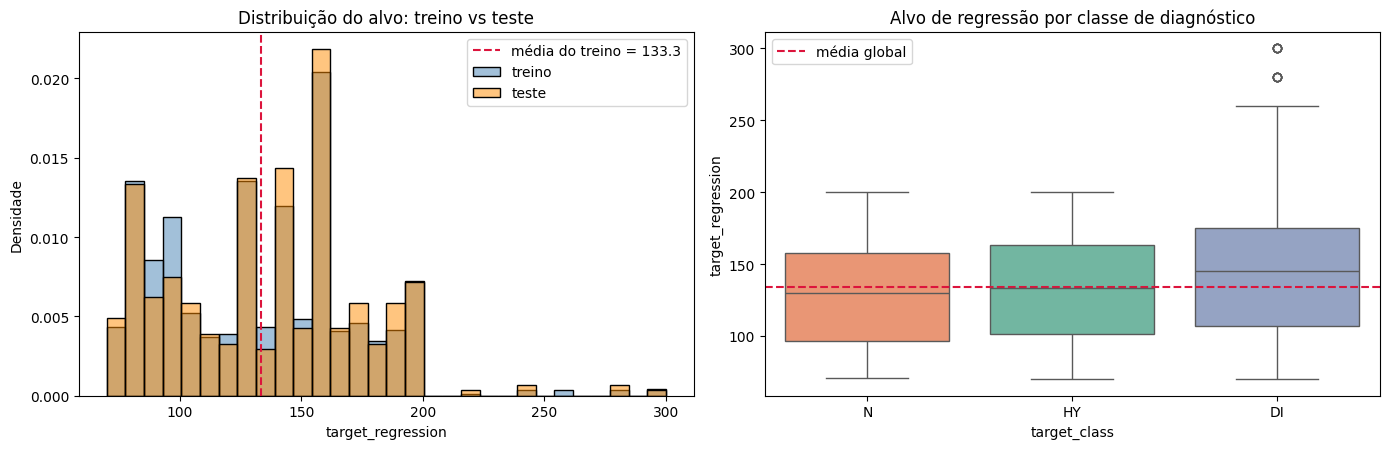

In [5]:
# ============================================================
# VISUAL: TARGET DISTRIBUTION (TRAIN VS TEST) AND TARGET BY CLASS
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

sns.histplot(y_train, bins=30, stat="density", color="steelblue", alpha=0.5, label="treino", ax=axes[0])
sns.histplot(y_test, bins=30, stat="density", color="darkorange", alpha=0.5, label="teste", ax=axes[0])
axes[0].axvline(y_train.mean(), color="crimson", ls="--", label=f"média do treino = {y_train.mean():.1f}")
axes[0].set(title="Distribuição do alvo: treino vs teste", xlabel=target, ylabel="Densidade")
axes[0].legend()

sns.boxplot(data=df, x="target_class", y=target, order=["N", "HY", "DI"], hue="target_class",
            palette="Set2", legend=False, ax=axes[1])
axes[1].axhline(df[target].mean(), color="crimson", ls="--", label="média global")
axes[1].set(title="Alvo de regressão por classe de diagnóstico", xlabel="target_class", ylabel=target)
axes[1].legend()

plt.tight_layout()
plt.show()

**Leitura do gráfico:** treino e teste têm distribuições praticamente iguais, pelo que a partição é representativa. O alvo não tem forma de campânula: concentra-se em alguns picos (em torno de 85, 130 e 160) e tem uma cauda curta até 300. Por classe, só `DI` se destaca (mediana mais alta e mais dispersão); `N` e `HY` quase coincidem. Um alvo com esta forma dificilmente é uma função suave das *features*.

---
## 2. O modelo e a forma matricial

Com $p$ preditores, o modelo é $Y = \beta_0 + \beta_1 X_1 + \dots + \beta_p X_p + \varepsilon$. Os coeficientes estimam-se minimizando a soma dos quadrados dos resíduos,

$$RSS = \sum_i \left(y_i - \hat\beta_0 - \hat\beta_1 x_{i1} - \dots - \hat\beta_p x_{ip}\right)^2.$$

Na forma matricial, $\hat\beta = (X^T X)^{-1} X^T y$, que só tem solução única se $X^T X$ for **não singular**, ou seja, se as colunas de $X$ (incluindo a coluna de 1s do termo constante) forem linearmente independentes. Verifica-se se isso acontece com todas as variáveis numéricas.

In [6]:
# ============================================================
# IS X^T X NON-SINGULAR WITH ALL NUMERICAL PREDICTORS?
# ============================================================
X_all = sm.add_constant(train[predictors], has_constant="add")
rank = np.linalg.matrix_rank(X_all.values)

print(f"Colunas de X (com termo constante): {X_all.shape[1]} | característica (rank): {rank}")
print("Variáveis constantes:", [col for col in predictors if train[col].nunique() == 1])

Colunas de X (com termo constante): 35 | característica (rank): 33
Variáveis constantes: ['calcium_baseline']


**Leitura:** a característica é inferior ao número de colunas, ou seja, existem colunas linearmente dependentes e $X^T X$ é singular. Uma variável constante (`calcium_baseline`) é combinação linear da coluna de 1s. As outras causas aparecem na secção seguinte. As variáveis codificadas não contribuem para a singularidade porque se retirou uma categoria de referência em cada *one-hot*.

---
## 3. Correlação entre preditores

Como no exemplo *Advertising* (`advertising.corr()`), observa-se a correlação entre preditores, porque preditores muito correlacionados podem fazer uma variável parecer não significativa. Vê-se também a correlação de cada preditor com o alvo.

**Notação:** $r$ (minúsculo) é o coeficiente de correlação de Pearson entre **duas** variáveis (entre -1 e +1). $R^2$ (maiúsculo, secções 4 a 6) é a fração da variância do alvo explicada pelo **modelo** com todos os preditores.

Pares de preditores com |r| >= 0.80:


,Variável 1,Variável 2,r entre preditores
0,age,age_normalized,1.0
1,systolic_bp,systolic_index,1.0


Correlação de cada preditor com o alvo (ordenada por |r|):


,r com o alvo
HbA1c_level,0.0913
employment_status_Retired,-0.0603
sleep_hours,0.0537
bmi,0.0519
employment_status_Employed,0.0513
stress_level,-0.0395
diastolic_bp,0.0379
high_ldl_cholesterol,-0.0329
age_normalized,0.0326
age,0.0326


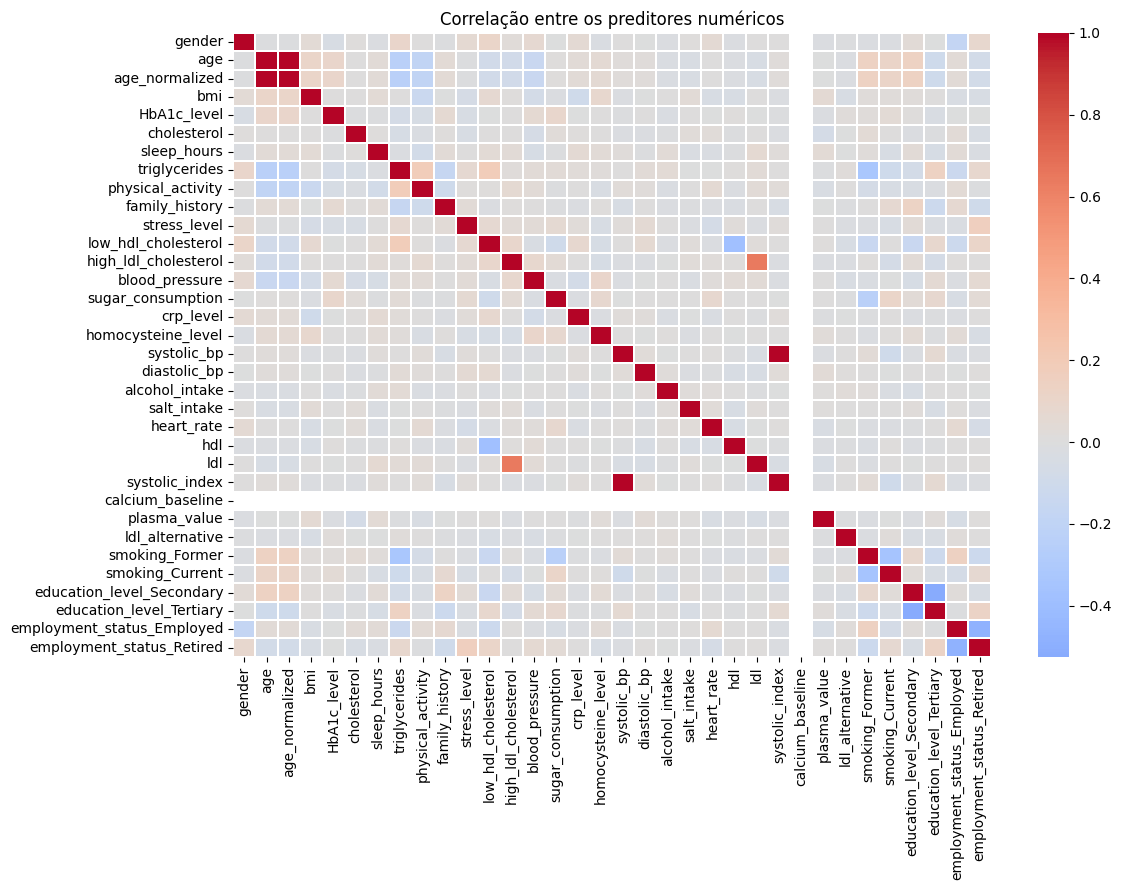

In [7]:
# ============================================================
# CORRELATION AMONG PREDICTORS AND WITH THE TARGET (TRAINING SET)
# ============================================================
corr = train[predictors + [target]].corr()

pairs = (
    corr.loc[predictors, predictors]
    .where(np.triu(np.ones((len(predictors), len(predictors)), dtype=bool), k=1))
    .stack()
    .rename("r entre preditores")
    .reset_index()
)
pairs.columns = ["Variável 1", "Variável 2", "r entre preditores"]
print("Pares de preditores com |r| >= 0.80:")
display(pairs[pairs["r entre preditores"].abs() >= 0.80].round(4).reset_index(drop=True))

target_corr = corr[target].drop(target).dropna().sort_values(key=abs, ascending=False)
print("Correlação de cada preditor com o alvo (ordenada por |r|):")
display(target_corr.round(4).to_frame("r com o alvo"))

plt.figure(figsize=(12, 9))
sns.heatmap(corr.loc[predictors, predictors], cmap="coolwarm", center=0, linewidths=0.3)
plt.title("Correlação entre os preditores numéricos")
plt.tight_layout()
plt.show()

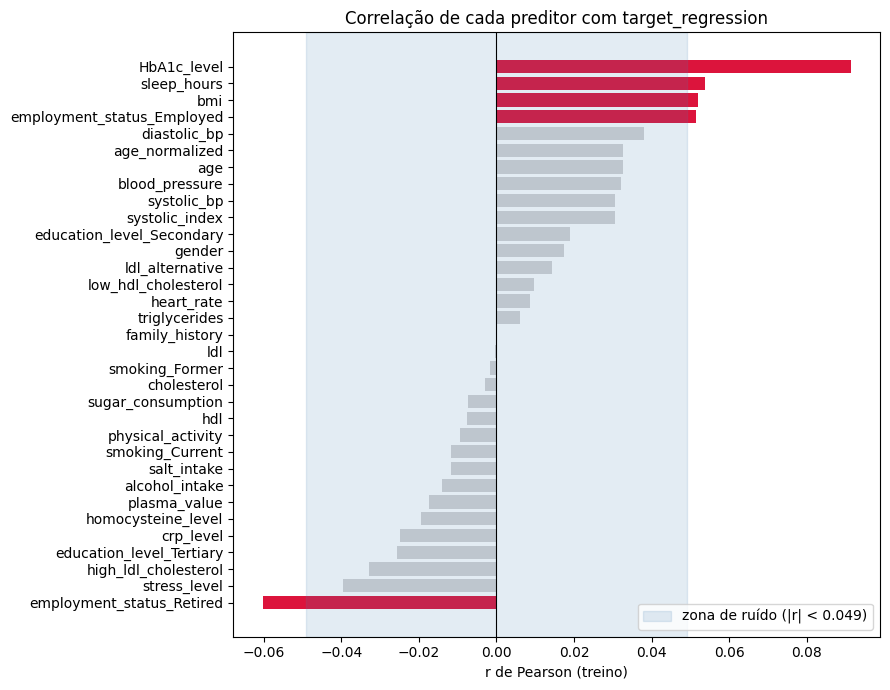

In [8]:
# ============================================================
# VISUAL: CORRELATION WITH THE TARGET VS "NOISE BAND"
# ============================================================
band = 1.96 / np.sqrt(len(train))  # com r = 0 na população, 95% dos |r| amostrais ficam abaixo disto

plot_corr = target_corr.sort_values()
colors = ["crimson" if abs(v) > band else "lightgrey" for v in plot_corr.values]

plt.figure(figsize=(9, 7))
plt.barh(plot_corr.index, plot_corr.values, color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.axvspan(-band, band, color="steelblue", alpha=0.15, label=f"zona de ruído (|r| < {band:.3f})")
plt.title("Correlação de cada preditor com target_regression")
plt.xlabel("r de Pearson (treino)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Leitura do gráfico:** a faixa azul é a zona onde se esperam correlações só por acaso (com 1600 observações, $|r| < 1{,}96/\sqrt{n} \approx 0{,}049$). Apenas `HbA1c_level`, `employment_status_Retired`, `sleep_hours`, `bmi` e `employment_status_Employed` saem da faixa, e o maior $r$ (≈ 0,09) corresponde a $r^2 \approx 0{,}8\%$ da variância. Todos os outros preditores, incluindo a maioria dos codificados, são indistinguíveis de ruído.

**Leitura:**
- `age` e `age_normalized` têm $r = 1$ (a segunda é a primeira em escala 0-1), tal como `systolic_bp` e `systolic_index`. São colunas redundantes e explicam a singularidade de $X^T X$.
- A correlação de cada preditor com o alvo é muito baixa (o maior $|r|$ é `HbA1c_level`, abaixo de 0,10), pelo que não se espera um $R^2$ elevado.
- Fora os pares redundantes, os preditores (incluindo os codificados) têm correlações fracas entre si, por isso não há outro problema de colinearidade relevante.

Para obter um modelo com solução única retiram-se uma variável constante (`calcium_baseline`) e uma de cada par redundante (`age_normalized`, `systolic_index`). Ficam 31 preditores (`clean`): 18 numéricos e 13 codificados.

In [9]:
# ============================================================
# PREDICTORS WITHOUT CONSTANT / REDUNDANT COLUMNS
# ============================================================
drop = ["calcium_baseline", "age_normalized", "systolic_index"]
clean = [col for col in predictors if col not in drop]

X_clean = sm.add_constant(train[clean])
print(f"Preditores: {len(clean)} | colunas de X: {X_clean.shape[1]} | rank: {np.linalg.matrix_rank(X_clean.values)}")

Preditores: 31 | colunas de X: 32 | rank: 32


### Escala dos preditores: estão normalizados?

Os preditores têm unidades muito diferentes. Verifica-se se estão normalizados (média 0 e desvio-padrão 1, ou escala 0-1) e se isso afeta o modelo. As estatísticas calculam-se só no treino.


In [10]:
# ============================================================
# SCALE OF THE PREDICTORS (TRAINING SET) AND INVARIANCE OF OLS TO SCALING
# ============================================================
from sklearn.preprocessing import StandardScaler

scale = train[clean].agg(["mean", "std", "min", "max"]).T
display(scale.sort_values("std", ascending=False).round(3))
print(f"Desvio-padrão dos preditores: de {scale['std'].min():.2f} a {scale['std'].max():.2f}")

scaler = StandardScaler().fit(train[clean])
raw_model = skl_lm.LinearRegression().fit(train[clean], y_train)
std_model = skl_lm.LinearRegression().fit(scaler.transform(train[clean]), y_train)
same = np.allclose(raw_model.predict(test[clean]), std_model.predict(scaler.transform(test[clean])))
print(f"Previsões no teste iguais com e sem normalização: {same}")


,mean,std,min,max
triglycerides,184.031,66.538,50.000,389.000
cholesterol,223.218,33.049,150.000,299.000
ldl,129.676,25.705,70.000,189.000
ldl_alternative,129.258,25.556,70.000,189.000
age,48.268,21.807,2.000,89.000
systolic_bp,133.763,19.477,90.000,179.000
hdl,64.234,14.889,30.000,99.000
diastolic_bp,89.003,12.370,60.000,119.000
heart_rate,74.639,10.336,50.000,99.000
bmi,27.534,7.191,14.400,87.700


Desvio-padrão dos preditores: de 0.15 a 66.54
Previsões no teste iguais com e sem normalização: True


**Leitura:** os preditores **não** estão normalizados. Além das variáveis codificadas (0/1 nas binárias e *dummies*, 1 a 3 nas ordinais), só `age_normalized` está numa escala 0-1, e essa já foi retirada. Os restantes têm desvios-padrão de 0,15 (`plasma_value`) a 66,5 (`triglycerides`).

Para mínimos quadrados isto não é problema: as previsões (e portanto $R^2$, MAE e RMSE) são iguais com e sem normalização, como se verificou, porque reescalar uma coluna só reescala o seu coeficiente. Por isso o modelo usa as variáveis originais e os coeficientes ficam nas unidades de cada preditor. A normalização só importa para comparar coeficientes (secção 4, com preditores padronizados) e passa a ser necessária em métodos com penalização, como Ridge e Lasso.

---
## 4. Pergunta 1: que preditores são úteis?

Ajusta-se o modelo com todos os preditores `clean` por mínimos quadrados com `statsmodels` (como em `smf.ols('sales ~ TV + radio + newspaper', ...)`). Para cada coeficiente testa-se $H_0: \beta_j = 0$ (sem relação com $Y$) e a estatística F testa se pelo menos um coeficiente é diferente de zero. Um p-value pequeno (tipicamente $< 0{,}05$) leva a rejeitar $H_0$.

In [11]:
# ============================================================
# STATSMODELS OLS - ALL "CLEAN" PREDICTORS
# ============================================================
est = smf.ols(f"{target} ~ " + " + ".join(clean), train).fit()

print(f"R2 = {est.rsquared:.4f} | R2 ajustado = {est.rsquared_adj:.4f} | F = {est.fvalue:.2f} (p = {est.f_pvalue:.4f})")
display(est.summary().tables[1])

R2 = 0.0306 | R2 ajustado = 0.0114 | F = 1.60 (p = 0.0201)


,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,22.1233,49.851,0.444,0.657,-75.658,119.904
gender,1.9828,1.993,0.995,0.320,-1.927,5.893
age,0.0395,0.048,0.826,0.409,-0.054,0.133
bmi,0.2746,0.139,1.976,0.048,0.002,0.547
HbA1c_level,3.9346,1.129,3.486,0.001,1.720,6.149
cholesterol,-0.0035,0.029,-0.119,0.906,-0.061,0.054
sleep_hours,1.5160,0.724,2.093,0.037,0.095,2.937
triglycerides,0.0084,0.017,0.499,0.618,-0.025,0.041
physical_activity,-0.0780,1.230,-0.063,0.949,-2.490,2.334
family_history,-0.9401,2.015,-0.467,0.641,-4.892,3.012


**Como ler a tabela:** cada linha é um preditor (mais o `Intercept`) e cada coluna responde a uma pergunta.

| Coluna | Pergunta a que responde | Como ler |
|---|---|---|
| `coef` | Quanto muda o alvo quando o preditor sobe 1 unidade, com os outros fixos? | O sinal dá a direção e o valor dá o tamanho do efeito. |
| `std err` | Quão incerta é essa estimativa? | Quanto menor, mais fiável o `coef`. |
| `t` | A quantos erros-padrão está o `coef` de 0? | $t = \text{coef} / \text{std err}$. Um $\lvert t\rvert$ acima de cerca de 2 destaca-se do ruído. |
| `P>\|t\|` | Se o preditor não tivesse efeito, qual a probabilidade de ver um valor assim só por acaso? | Abaixo de 0,05 rejeita-se $H_0$ (efeito "significativo"). |
| `[0.025  0.975]` | Entre que valores está o verdadeiro coeficiente (intervalo de confiança a 95%)? | Se o intervalo inclui 0, o efeito não se distingue de "nenhum efeito". |

O `Intercept` é o valor previsto do alvo quando todos os preditores valem 0. Não é um preditor e não se usa para escolher variáveis.

In [12]:
# ============================================================
# SIGNIFICANT PREDICTORS (p < 0.05)
# ============================================================
pvalues = est.pvalues.drop("Intercept").sort_values()
significant = pvalues[pvalues < 0.05].index.tolist()

print("Preditores com p-value < 0.05:", significant)
display(pvalues.round(4).to_frame("p-value"))

Preditores com p-value < 0.05: ['HbA1c_level', 'sleep_hours', 'high_ldl_cholesterol', 'bmi']


,p-value
HbA1c_level,0.0005
sleep_hours,0.0365
high_ldl_cholesterol,0.0372
bmi,0.0484
blood_pressure,0.0641
employment_status_Employed,0.1087
diastolic_bp,0.1161
homocysteine_level,0.1200
stress_level,0.1889
systolic_bp,0.2025


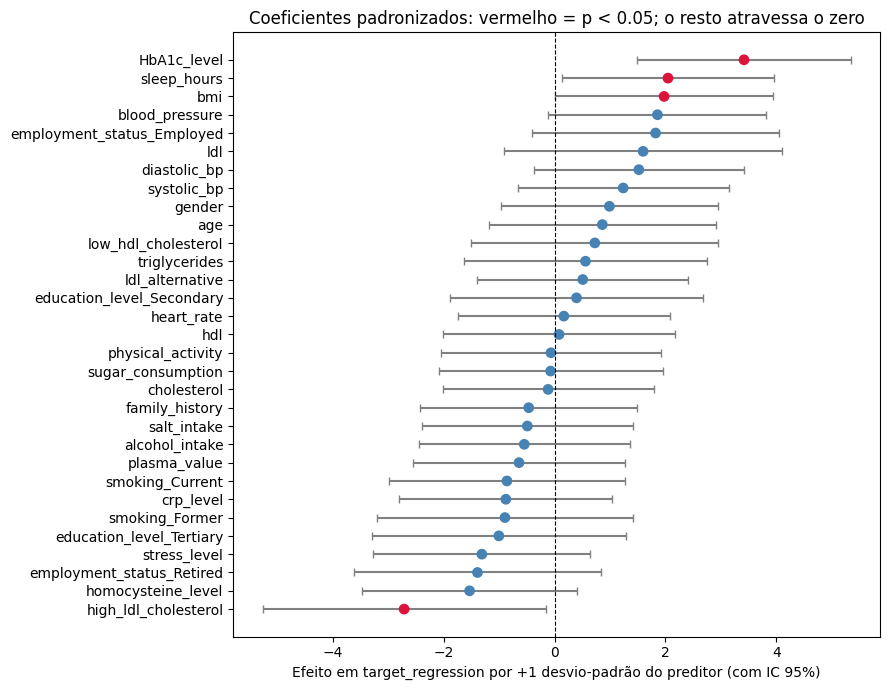

In [13]:
# ============================================================
# VISUAL: COEFFICIENTS WITH 95% CONFIDENCE INTERVALS (STANDARDISED PREDICTORS)
# ============================================================
z = train[clean].copy()
z = (z - z.mean()) / z.std()
z[target] = y_train.values
est_z = smf.ols(f"{target} ~ " + " + ".join(clean), z).fit()

coef = est_z.params.drop("Intercept")
ci = est_z.conf_int().drop("Intercept")
order = coef.sort_values().index
sig = est_z.pvalues[order] < 0.05

plt.figure(figsize=(9, 7))
plt.errorbar(coef[order], range(len(order)),
             xerr=[coef[order] - ci.loc[order, 0], ci.loc[order, 1] - coef[order]],
             fmt="none", ecolor="grey", capsize=3, zorder=1)
plt.scatter(coef[order], range(len(order)), c=np.where(sig, "crimson", "steelblue"), zorder=2, s=45)
plt.axvline(0, color="black", ls="--", lw=0.8)
plt.yticks(range(len(order)), order)
plt.xlabel(f"Efeito em {target} por +1 desvio-padrão do preditor (com IC 95%)")
plt.title("Coeficientes padronizados: vermelho = p < 0.05; o resto atravessa o zero")
plt.tight_layout()
plt.show()

**Leitura do gráfico:** com os preditores padronizados, os coeficientes ficam todos na mesma escala (efeito no alvo por +1 desvio-padrão do preditor) e podem comparar-se. O maior (`HbA1c_level`, ≈ +3,4) é pequeno face ao desvio-padrão do alvo (≈ 39). Os intervalos de confiança de 27 dos 31 preditores incluem o zero, o que é a versão visual dos p-values acima de 0,05.

**Leitura:** o teste F rejeita $H_0$ ao nível de 5% (p ≈ 0,020), mas $R^2$ é muito baixo (0,031) e o $R^2$ ajustado é ainda menor (0,011), porque penaliza os 31 preditores. Apenas `HbA1c_level`, `sleep_hours`, `high_ldl_cholesterol` e `bmi` têm p-value inferior a 0,05 (`bmi` por pouco, 0,048), e os restantes não mostram relação significativa com `target_regression` quando os outros preditores estão no modelo. Entre as variáveis codificadas só `high_ldl_cholesterol` se destaca, com efeito negativo (≈ -5,4). Com 31 testes, esperam-se cerca de 1,5 resultados "significativos" só por acaso, por isso estes quatro preditores devem ser lidos com cautela.

---
## 5. Pergunta 2: todos os preditores ou só um subconjunto?

Experimentam-se várias combinações de preditores, ajustadas no treino com `LinearRegression` e avaliadas no teste com $R^2$, MAE e RMSE:

- todos os preditores, numéricos e codificados (modelo da secção 2, com colunas redundantes);
- `clean` (sem constante nem redundantes);
- `clean` sem as variáveis codificadas, para medir o contributo das categóricas;
- apenas os preditores significativos da pergunta 1;
- os $k$ preditores mais correlacionados com o alvo no treino ($k = 1, 2, 3, 5$).

Como referência inclui-se o modelo que prevê sempre a média do treino (corresponde a $R^2 = 0$ no treino).

In [14]:
# ============================================================
# COMPARISON OF PREDICTOR COMBINATIONS (HOLD-OUT)
# ============================================================
def rmse(y_true, y_pred):
    return mean_squared_error(y_true, y_pred) ** 0.5

def evaluate(cols):
    model = skl_lm.LinearRegression().fit(train[cols], y_train)
    pred_train, pred_test = model.predict(train[cols]), model.predict(test[cols])
    return {
        "nº preditores": len(cols),
        "R2 treino": r2_score(y_train, pred_train),
        "R2 teste": r2_score(y_test, pred_test),
        "MAE teste": mean_absolute_error(y_test, pred_test),
        "RMSE teste": rmse(y_test, pred_test),
    }

ranked_by_corr = train[clean].corrwith(y_train).abs().sort_values(ascending=False).index.tolist()
combinations = {
    "Todas": predictors,
    "clean": clean,
    "clean sem categóricas": [c for c in clean if c in df.select_dtypes("number").columns],
    "Significativas (p < 0.05)": significant,
    "Top-1 correlação": ranked_by_corr[:1],
    "Top-2 correlação": ranked_by_corr[:2],
    "Top-3 correlação": ranked_by_corr[:3],
    "Top-5 correlação": ranked_by_corr[:5],
}

results = pd.DataFrame({name: evaluate(cols) for name, cols in combinations.items()}).T
results["nº preditores"] = results["nº preditores"].astype(int)

baseline_pred = np.full(len(test), y_train.mean())
results.loc["Baseline (média do treino)"] = [0, 0.0, r2_score(y_test, baseline_pred),
                                              mean_absolute_error(y_test, baseline_pred), rmse(y_test, baseline_pred)]
display(results.round(4))

best_name = results.drop("Baseline (média do treino)")["RMSE teste"].idxmin()
best_cols = combinations[best_name]
print(f"Melhor combinação (menor RMSE no teste): {best_name} -> {best_cols}")

,nº preditores,R2 treino,R2 teste,MAE teste,RMSE teste
Todas,34.0,0.0307,0.0092,32.2848,38.8867
clean,31.0,0.0306,0.0063,32.3367,38.9421
clean sem categóricas,18.0,0.0205,0.0148,32.0986,38.7756
Significativas (p < 0.05),4.0,0.0150,0.0202,32.0733,38.6687
Top-1 correlação,1.0,0.0083,0.0209,31.8686,38.6552
Top-2 correlação,2.0,0.0119,0.0181,31.9837,38.7116
Top-3 correlação,3.0,0.0147,0.0180,32.0442,38.7135
Top-5 correlação,5.0,0.0177,0.0185,32.0193,38.7024
Baseline (média do treino),0.0,0.0000,-0.0068,32.2355,39.1987


Melhor combinação (menor RMSE no teste): Top-1 correlação -> ['HbA1c_level']


In [15]:
# ============================================================
# COLUMNS USED IN EACH COMBINATION
# ============================================================
def describe(cols):
    if len(cols) <= 5:
        return ", ".join(cols)
    excluded = [c for c in predictors if c not in cols]
    if not excluded:
        return f"todas as {len(cols)}"
    return f"todas menos {', '.join(excluded)}" if len(excluded) <= 5 else f"{len(cols)} de {len(predictors)} preditores"

print("Ordem dos preditores por |r| com o alvo (treino):")
display(train[clean].corrwith(y_train).reindex(ranked_by_corr).round(4).to_frame("r com o alvo").head(5))

with pd.option_context("display.max_colwidth", None):
    display(pd.Series({name: describe(cols) for name, cols in combinations.items()}, name="colunas usadas").to_frame())

Ordem dos preditores por |r| com o alvo (treino):


,r com o alvo
HbA1c_level,0.0913
employment_status_Retired,-0.0603
sleep_hours,0.0537
bmi,0.0519
employment_status_Employed,0.0513


,colunas usadas
Todas,todas as 34
clean,"todas menos age_normalized, systolic_index, calcium_baseline"
clean sem categóricas,18 de 34 preditores
Significativas (p < 0.05),"HbA1c_level, sleep_hours, high_ldl_cholesterol, bmi"
Top-1 correlação,HbA1c_level
Top-2 correlação,"HbA1c_level, employment_status_Retired"
Top-3 correlação,"HbA1c_level, employment_status_Retired, sleep_hours"
Top-5 correlação,"HbA1c_level, employment_status_Retired, sleep_hours, bmi, employment_status_Employed"


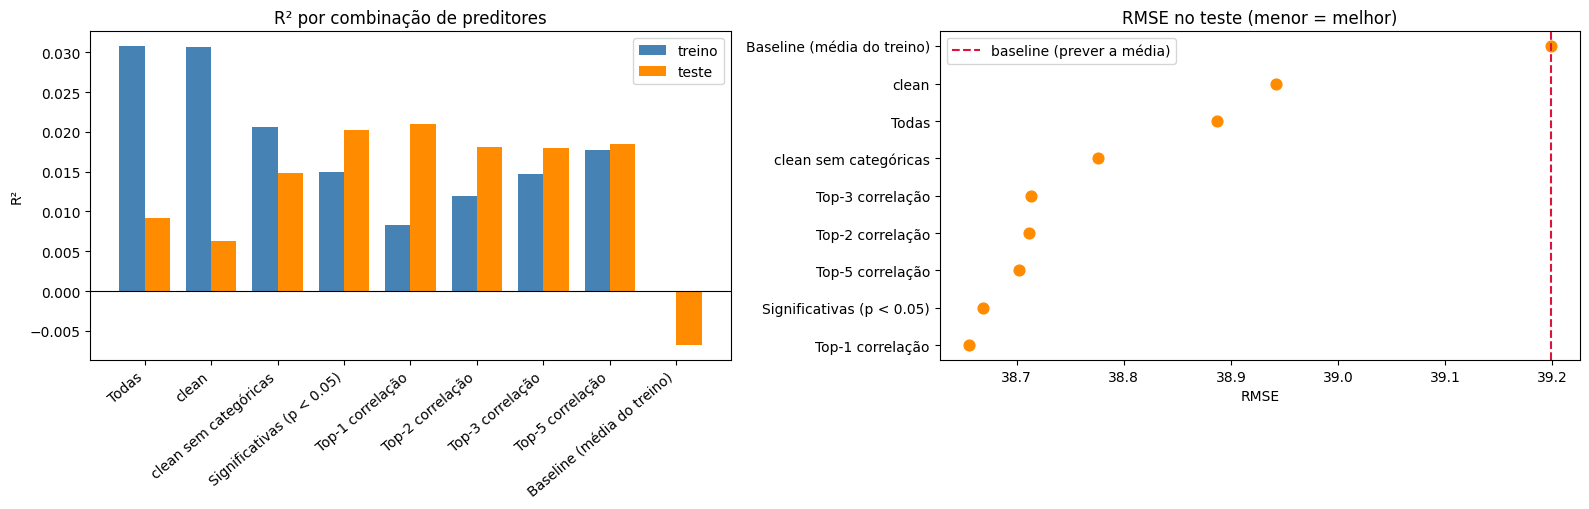

In [16]:
# ============================================================
# VISUAL: COMPARISON OF PREDICTOR COMBINATIONS
# ============================================================
plot_res = results.copy()
labels = plot_res.index.tolist()
x = np.arange(len(labels))
w = 0.38

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))

axes[0].bar(x - w / 2, plot_res["R2 treino"], w, label="treino", color="steelblue")
axes[0].bar(x + w / 2, plot_res["R2 teste"], w, label="teste", color="darkorange")
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, rotation=40, ha="right")
axes[0].set(title="R² por combinação de preditores", ylabel="R²")
axes[0].legend()

ordered = plot_res["RMSE teste"].sort_values()
axes[1].scatter(ordered.values, range(len(ordered)), s=60, color="darkorange", zorder=2)
axes[1].axvline(plot_res.loc["Baseline (média do treino)", "RMSE teste"], color="crimson", ls="--",
                label="baseline (prever a média)")
axes[1].set_yticks(range(len(ordered)))
axes[1].set_yticklabels(ordered.index)
axes[1].set(title="RMSE no teste (menor = melhor)", xlabel="RMSE")
axes[1].legend()

plt.tight_layout()
plt.show()

**Leitura do gráfico:** o $R^2$ de teste fica entre cerca de 0,006 e 0,021 em todas as combinações, contra aproximadamente -0,007 do modelo de referência. No RMSE, a diferença entre a melhor e a pior combinação (≈ 0,29) é comparável à diferença de cada uma para a referência (≈ 0,26 a 0,54). Os modelos com mais preditores (`Todas`, `clean`) têm o $R^2$ de treino mais alto (0,031) e o de teste mais baixo, o sinal típico de ajuste a ruído.

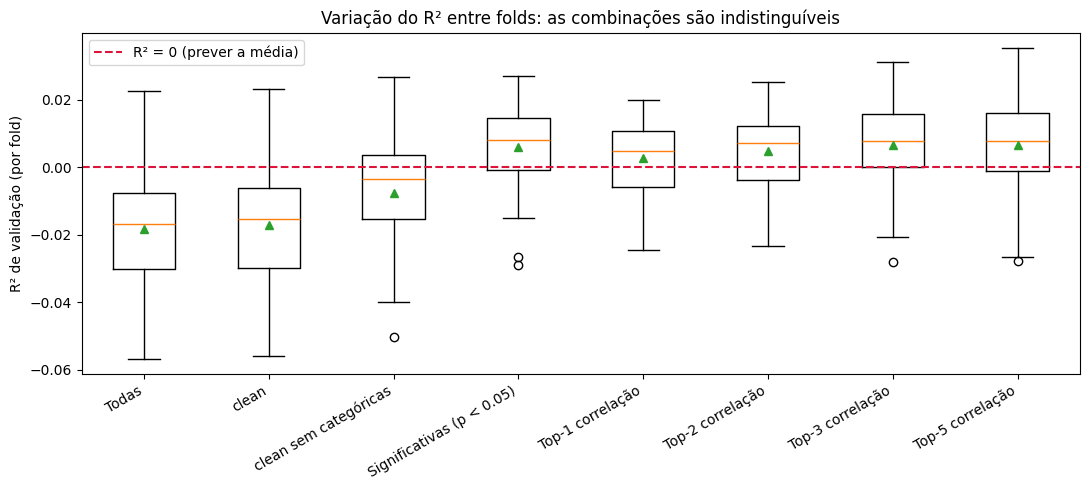

R² médio de validação cruzada (treino):


,média,desvio-padrão
Todas,-0.0182,0.0178
clean,-0.0170,0.0176
clean sem categóricas,-0.0075,0.0157
Significativas (p < 0.05),0.0060,0.0125
Top-1 correlação,0.0027,0.0104
Top-2 correlação,0.0048,0.0112
Top-3 correlação,0.0065,0.0125
Top-5 correlação,0.0067,0.0133


In [17]:
# ============================================================
# VISUAL: HOW MUCH DOES R2 VARY ACROSS FOLDS? (5-FOLD x 10, TRAINING SET ONLY)
# ============================================================
from sklearn.model_selection import RepeatedKFold, cross_val_score

cv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
cv_scores = {
    name: cross_val_score(skl_lm.LinearRegression(), train[cols], y_train, cv=cv, scoring="r2")
    for name, cols in combinations.items()
}

plt.figure(figsize=(11, 5))
plt.boxplot(list(cv_scores.values()), tick_labels=list(cv_scores.keys()), showmeans=True)
plt.axhline(0, color="crimson", ls="--", label="R² = 0 (prever a média)")
plt.xticks(rotation=30, ha="right")
plt.ylabel("R² de validação (por fold)")
plt.title("Variação do R² entre folds: as combinações são indistinguíveis")
plt.legend()
plt.tight_layout()
plt.show()

print("R² médio de validação cruzada (treino):")
display(pd.DataFrame({k: {"média": v.mean(), "desvio-padrão": v.std()} for k, v in cv_scores.items()}).T.round(4))

**Leitura do gráfico:** a validação cruzada repetida (5 folds x 10, só no treino) mostra que o $R^2$ varia de fold para fold entre cerca de -0,06 e +0,04, uma variação maior do que as diferenças entre combinações. As médias ficam entre -0,017 (`Todas` e `clean`, com 31 a 34 preditores) e +0,007 (`Top-5` e `Top-3`), isto é, praticamente zero. Conclusão: escolher `Top-1` pelo menor RMSE no teste foi uma escolha dentro do ruído, e nenhuma combinação supera de forma fiável a previsão pela média.

**Leitura:**
- Todas as combinações têm $R^2$ de teste entre 0,006 e 0,021, e RMSE e MAE só ligeiramente abaixo dos do modelo de referência. As diferenças entre combinações são pequenas.
- "Todas" e `clean` dão exatamente os mesmos resultados: as colunas redundantes não acrescentam informação, e o `scikit-learn` resolve a singularidade com uma solução particular que dá as mesmas previsões. Retirar essas colunas serve para obter coeficientes únicos e interpretáveis, e não para melhorar a previsão.
- As variáveis codificadas não ajudam: `clean` (31 preditores) tem $R^2$ de treino 0,031 contra 0,021 de `clean sem categóricas` (18), mas o $R^2$ de teste desce de 0,015 para 0,006 e o RMSE sobe de 38,78 para 38,94. Os 13 preditores acrescentados ajustam sobretudo ruído, tal como acontece em geral quando se juntam preditores sem relação com o alvo.
- A escolha foi feita com o RMSE no conjunto de teste, que é o único conjunto fora do treino. Como as diferenças são pequenas e há poucas combinações, o enviesamento desta escolha é pequeno, mas o desempenho do modelo escolhido pode estar ligeiramente otimista.

---
## 6. Pergunta 3: quão bem se ajusta o modelo?

$R^2$ é a proporção da variância explicada pelo modelo, $R^2 = (TSS - RSS)/TSS = 1 - RSS/TSS$, com $TSS = \sum (y_i - \bar y)^2$. Calcula-se para o modelo escolhido, e ajusta-se também com `statsmodels` para ver coeficientes, p-values e estatística F.

In [18]:
# ============================================================
# R2 = 1 - RSS/TSS FOR THE CHOSEN MODEL
# ============================================================
final = skl_lm.LinearRegression().fit(train[best_cols], y_train)
pred_train, pred_test = final.predict(train[best_cols]), final.predict(test[best_cols])

rss_train = ((y_train - pred_train) ** 2).sum()
tss_train = ((y_train - y_train.mean()) ** 2).sum()
print(f"Treino: RSS = {rss_train:,.0f} | TSS = {tss_train:,.0f} | R2 = 1 - RSS/TSS = {1 - rss_train / tss_train:.4f} (r2_score: {r2_score(y_train, pred_train):.4f})")

rss_test = ((y_test - pred_test) ** 2).sum()
tss_test = ((y_test - y_test.mean()) ** 2).sum()
print(f"Teste:  RSS = {rss_test:,.0f} | TSS = {tss_test:,.0f} | R2 = 1 - RSS/TSS = {1 - rss_test / tss_test:.4f}")

est_final = smf.ols(f"{target} ~ " + " + ".join(best_cols), train).fit()
print(f"\nF = {est_final.fvalue:.2f} (p = {est_final.f_pvalue:.4f}) | R2 ajustado = {est_final.rsquared_adj:.4f}")
display(est_final.summary().tables[1])

Treino: RSS = 2,367,226 | TSS = 2,387,113 | R2 = 1 - RSS/TSS = 0.0083 (r2_score: 0.0083)
Teste:  RSS = 597,690 | TSS = 610,464 | R2 = 1 - RSS/TSS = 0.0209

F = 13.42 (p = 0.0003) | R2 ajustado = 0.0077


,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,110.3688,6.329,17.438,0.000,97.955,122.783
HbA1c_level,4.0636,1.109,3.664,0.000,1.888,6.239


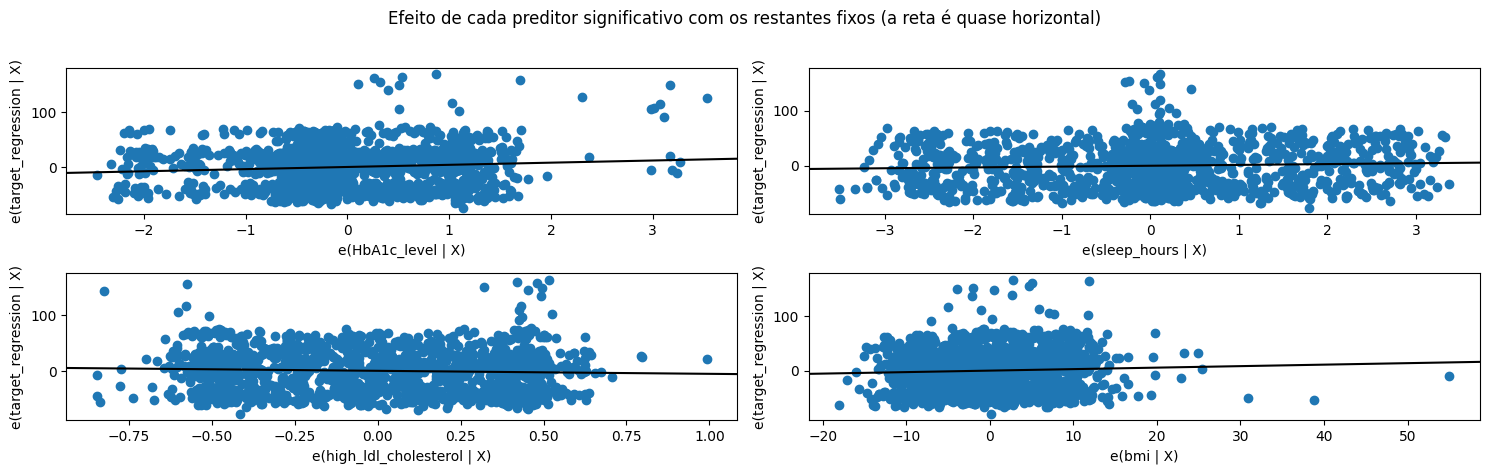

In [19]:
# ============================================================
# VISUAL: PARTIAL REGRESSION PLOTS (EFFECT OF EACH PREDICTOR, OTHERS HELD FIXED)
# ============================================================
fig = plt.figure(figsize=(15, 4.6))
sm.graphics.plot_partregress_grid(est, exog_idx=significant, fig=fig)
fig.suptitle("Efeito de cada preditor significativo com os restantes fixos (a reta é quase horizontal)", y=1.02)
plt.tight_layout()
plt.show()

**Leitura do gráfico:** cada painel mostra o efeito de um preditor depois de retirar o efeito dos restantes (é o sentido de "mantendo os outros fixos"), aqui no modelo completo da secção 4. Em todos a reta é quase horizontal face à nuvem de pontos, ou seja, o efeito existe mas é irrelevante na prática. Há alguns pontos extremos à direita (por exemplo `bmi` e `HbA1c_level`) que podem ter influência desproporcionada na reta.

**Leitura:** o modelo (só `HbA1c_level`) explica cerca de 1% da variância de `target_regression` no treino e 2% no teste: o preditor tem um efeito estatisticamente detetável (p-value e estatística F) mas muito pequeno em termos práticos. O $R^2$ calculado a partir de RSS e TSS coincide com `r2_score`. O $R^2$ de teste (0,021) é superior ao de treino (0,008), o que não indica sobreajuste: com um ajuste tão fraco, a diferença é variação aleatória da partição.

---
## 7. Pergunta 4: previsões

Dado um conjunto de valores dos preditores, o modelo devolve $\hat y = \hat\beta_0 + \hat\beta_1 x_1 + \dots + \hat\beta_p x_p$ (`model.predict`). Mostram-se previsões para observações do conjunto de teste, não vistas no treino, e o erro típico.

In [20]:
# ============================================================
# PREDICTIONS ON UNSEEN DATA
# ============================================================
sample = pd.DataFrame({"real": y_test.values[:8], "previsto": pred_test[:8]})
sample["erro"] = sample["real"] - sample["previsto"]
display(sample.round(2))

print(f"MAE = {mean_absolute_error(y_test, pred_test):.2f} | RMSE = {rmse(y_test, pred_test):.2f} "
      f"(desvio-padrão de {target} no teste: {y_test.std():.2f})")

,real,previsto,erro
0,160.0,135.56,24.44
1,126.0,133.94,-7.94
2,280.0,140.85,139.15
3,152.0,132.33,19.67
4,80.0,134.75,-54.75
5,80.0,130.69,-50.69
6,85.0,135.56,-50.56
7,158.0,135.56,22.44


MAE = 31.87 | RMSE = 38.66 (desvio-padrão de target_regression no teste: 39.12)


**Leitura:** o erro típico (MAE ≈ 32, RMSE ≈ 39) é da ordem do desvio-padrão do próprio alvo, ou seja, as previsões são pouco melhores do que prever sempre a média. Nas observações mostradas, as previsões ficam entre cerca de 130 e 141, enquanto os valores reais vão de 80 a 280.

---
## 8. Problemas potenciais do modelo

Os slides listam, entre outros, a **não linearidade** da relação resposta-preditor e a **variância não constante** dos erros. Observam-se os resíduos do treino face aos valores ajustados e as previsões face aos valores reais no teste.

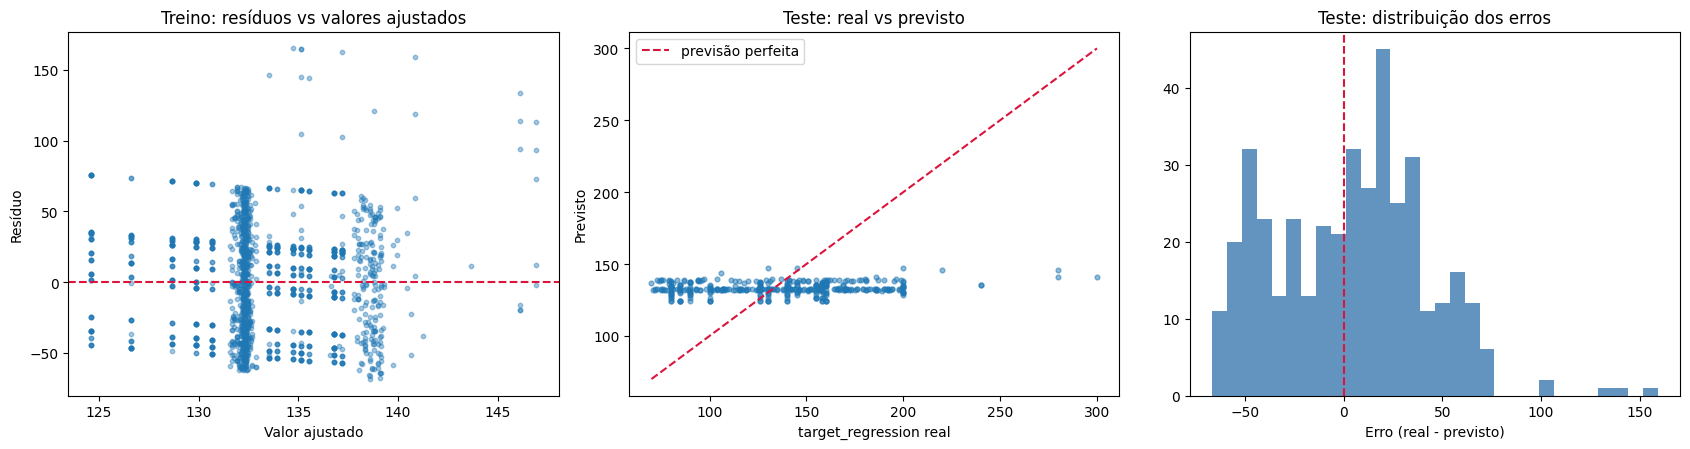

In [21]:
# ============================================================
# RESIDUALS AND PREDICTIONS
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

axes[0].scatter(pred_train, y_train - pred_train, s=10, alpha=0.4)
axes[0].axhline(0, color="crimson", ls="--")
axes[0].set(title="Treino: resíduos vs valores ajustados", xlabel="Valor ajustado", ylabel="Resíduo")

axes[1].scatter(y_test, pred_test, s=12, alpha=0.5)
lims = [y_test.min(), y_test.max()]
axes[1].plot(lims, lims, color="crimson", ls="--", label="previsão perfeita")
axes[1].set(title="Teste: real vs previsto", xlabel="target_regression real", ylabel="Previsto")
axes[1].legend()

axes[2].hist(y_test - pred_test, bins=30, color="steelblue", alpha=0.85)
axes[2].axvline(0, color="crimson", ls="--")
axes[2].set(title="Teste: distribuição dos erros", xlabel="Erro (real - previsto)")

plt.tight_layout()
plt.show()

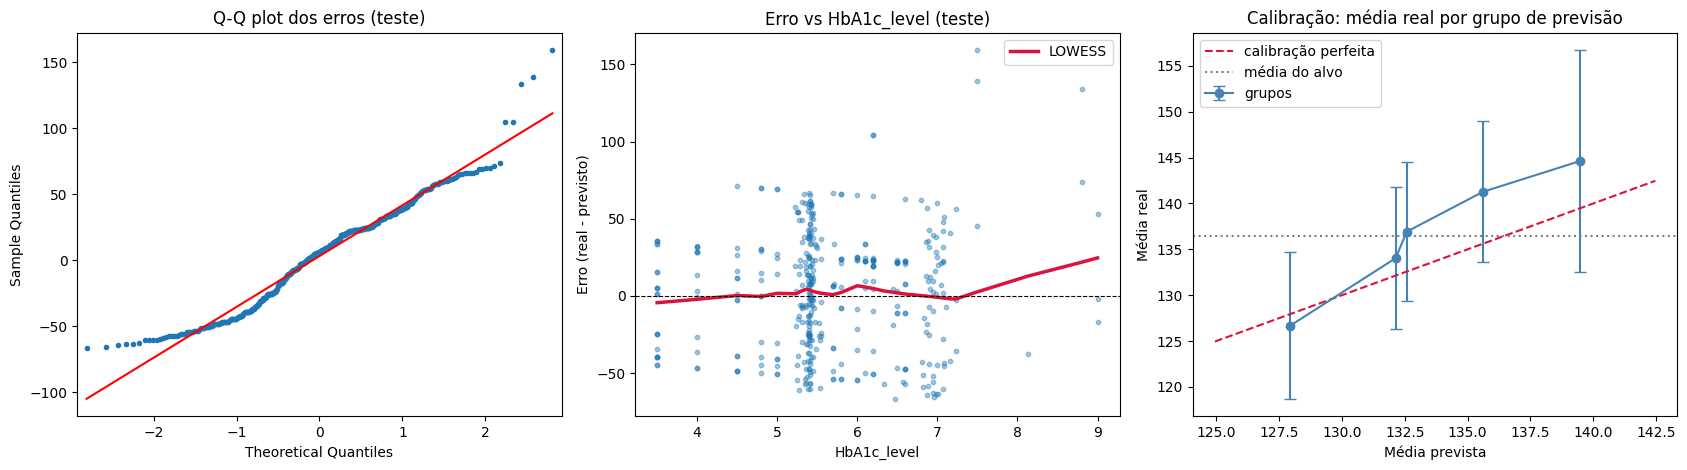

In [22]:
# ============================================================
# VISUAL: RESIDUAL DIAGNOSTICS (Q-Q, NON-LINEARITY CHECK, CALIBRATION)
# ============================================================
from statsmodels.nonparametric.smoothers_lowess import lowess

resid_test = y_test.values - pred_test
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# 1) Normalidade dos erros
sm.qqplot(resid_test, line="s", ax=axes[0], markersize=3)
axes[0].set_title("Q-Q plot dos erros (teste)")

# 2) Não linearidade: erro vs preditor mais correlacionado, com suavização LOWESS
main_pred = best_cols[0]
axes[1].scatter(test[main_pred], resid_test, s=10, alpha=0.4)
smooth = lowess(resid_test, test[main_pred], frac=0.5)
axes[1].plot(smooth[:, 0], smooth[:, 1], color="crimson", lw=2.5, label="LOWESS")
axes[1].axhline(0, color="black", ls="--", lw=0.8)
axes[1].set(title=f"Erro vs {main_pred} (teste)", xlabel=main_pred, ylabel="Erro (real - previsto)")
axes[1].legend()

# 3) Calibração: média real vs média prevista em 5 grupos de previsão
cal = pd.DataFrame({"prev": pred_test, "real": y_test.values})
cal["grupo"] = pd.qcut(cal["prev"], 5, duplicates="drop")
g = cal.groupby("grupo", observed=True).agg(prev=("prev", "mean"), real=("real", "mean"),
                                            se=("real", lambda s: s.std() / np.sqrt(len(s))))
axes[2].errorbar(g["prev"], g["real"], yerr=1.96 * g["se"], fmt="o-", capsize=4, color="steelblue", label="grupos")
lims = [g["prev"].min() - 3, g["prev"].max() + 3]
axes[2].plot(lims, lims, color="crimson", ls="--", label="calibração perfeita")
axes[2].axhline(y_test.mean(), color="grey", ls=":", label="média do alvo")
axes[2].set(title="Calibração: média real por grupo de previsão", xlabel="Média prevista", ylabel="Média real")
axes[2].legend()

plt.tight_layout()
plt.show()

**Leitura do gráfico:**
- **Q-Q plot:** os erros seguem a normal na zona central, mas com a cauda direita pesada (poucos valores muito acima do previsto, os alvos até 300) e a esquerda cortada (o alvo nunca é inferior a 70).
- **Erro vs `HbA1c_level`:** a curva LOWESS fica junto de zero, sem curvatura clara, pelo que este gráfico não indica não linearidade nesse preditor. A subida na zona final (> 7,5) apoia-se em muito poucos pontos.
- **Calibração:** a média real sobe com a previsão, mas só de forma ligeira (de ≈ 127 para ≈ 145) e os intervalos de confiança de cada grupo (± 8 a 12) sobrepõem-se quase todos. O modelo ordena de forma muito fraca.

**Leitura:** os valores ajustados ocupam uma faixa muito estreita, enquanto os valores reais se espalham por todo o intervalo, o que mostra que o modelo explica muito pouco do alvo. Os resíduos reproduzem a dispersão do próprio alvo. Neste dataset a relação entre os preditores e o alvo não é captada por um modelo linear.

---
## 9. Conclusões e discussão

- **Preditores úteis:** apenas `HbA1c_level`, `sleep_hours`, `high_ldl_cholesterol` e `bmi` têm relação estatisticamente significativa (p < 0,05) com `target_regression` no modelo completo, e o efeito de cada um é pequeno. Entre as variáveis categóricas codificadas só `high_ldl_cholesterol` se destaca.
- **Todos ou subconjunto:** a melhor combinação no teste foi `HbA1c_level` sozinho (Top-1), mas por uma margem mínima. Usar mais preditores não melhora o desempenho no teste, e as variáveis codificadas aumentam o $R^2$ de treino mas pioram o de teste. A colinearidade vem sobretudo de colunas redundantes (`age`/`age_normalized`, `systolic_bp`/`systolic_index`) e de uma constante (`calcium_baseline`), que se retiram para obter coeficientes únicos.
- **Escala:** os preditores não estão normalizados, mas isso não afeta a regressão linear por mínimos quadrados (as previsões são iguais com e sem normalização). Só seria necessário normalizar para comparar coeficientes ou usar Ridge e Lasso.
- **Ajuste:** $R^2$ ≈ 0,008 no treino e ≈ 0,021 no teste, e RMSE no teste de 38,66 (só com `HbA1c_level`), apenas ligeiramente inferior ao de prever sempre a média (39,20).
- **Interpretação:** a regressão linear múltipla explica muito pouco a variabilidade de `target_regression`. Os slides apontam a não linearidade como uma causa possível; verificar se termos polinomiais ou outras transformações melhoram o modelo fica fora do âmbito deste notebook.